In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = load_iris().data[:, 2:4]
X = StandardScaler().fit_transform(X)

In [2]:
inertias = []
sils = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))
    print(k, round(km.inertia_, 1), round(sils[-1], 3))

2 54.2 0.743
3 18.0 0.674
4 12.3 0.599
5 9.2 0.574
6 7.3 0.582
7 6.0 0.573
8 5.1 0.59


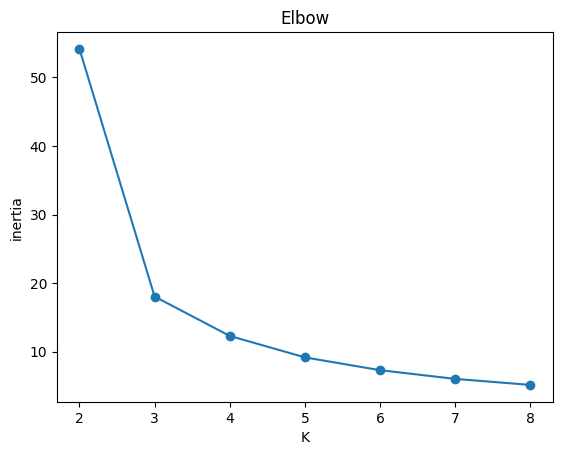

In [3]:
plt.plot(range(2, 9), inertias, marker="o")
plt.xlabel("K")
plt.ylabel("inertia")
plt.title("Elbow")
plt.show()

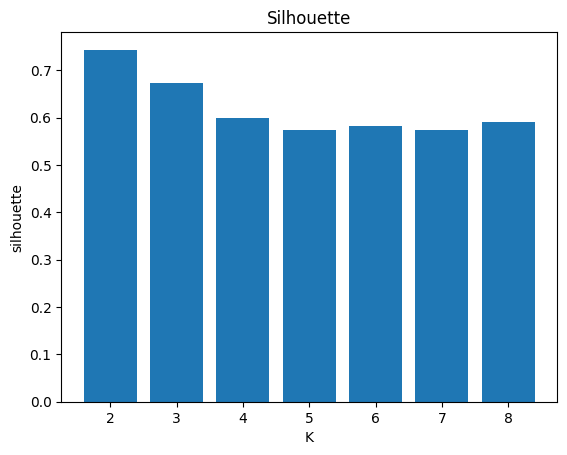

In [4]:
plt.bar(range(2, 9), sils)
plt.xlabel("K")
plt.ylabel("silhouette")
plt.title("Silhouette")
plt.show()

inertia: 18.0
silhouette: 0.674


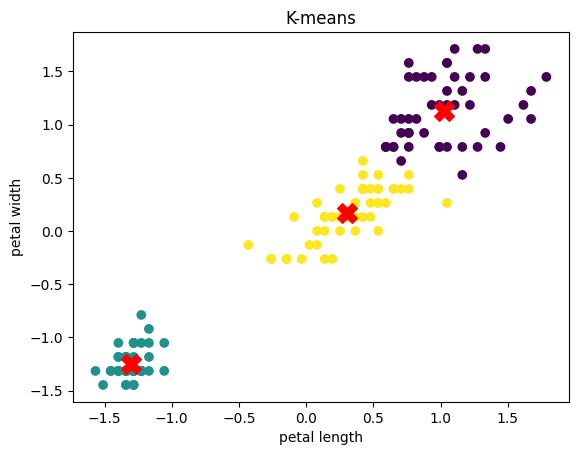

In [5]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
print("inertia:", round(km.inertia_, 1))
print("silhouette:", round(silhouette_score(X, km.labels_), 3))

plt.scatter(X[:, 0], X[:, 1], c=km.labels_)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c="red", marker="X", s=200)
plt.xlabel("petal length")
plt.ylabel("petal width")
plt.title("K-means")
plt.show()